A walkthrough of some of the cool things you can do in GeoPandas and why

First, import the library. Imports always go at the top of the project

In [30]:
%pip install geopandas

import geopandas as gpd
import pandas as pd

%matplotlib inline

states = gpd.read_file("states.geojson")

Note: you may need to restart the kernel to use updated packages.


Next, we write what's called a _magic command_. That's a piece of code that tells Jupyter to do something differently. Magic commands are always preceded with the `%` sign.

`%COMMAND ARGUMENT1, ARGUMENT2...`

In this case, we're simply going to tell Jupyter to display graphics "inline" as we make them. If we don't do that, then we won't be able to see the graphics without exporing them to a file, which is tedious if you're making lots of graphics or trying to iterate over a single one unti it's perfect.

<Axes: >

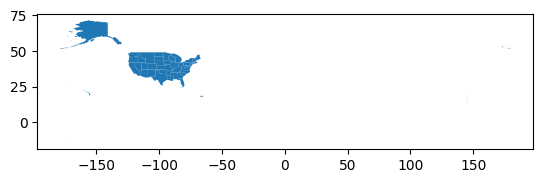

In [31]:
states.head()
states.plot()

GeoPandas works a lot like pandas. Reading a file is simple. Where in Pandas you used the `pd.read_csv()` method, here we use the `gpd.read_file` method.

In [32]:
print(states["STUSPS"].unique().tolist())

states = states[
    ~states["STUSPS"].isin(["AK", "HI", "GU", "PR", "VI", "MP", "AS"])
]

['NY', 'NV', 'AK', 'AS', 'VT', 'CT', 'DE', 'NM', 'NC', 'WI', 'OR', 'NE', 'GA', 'AL', 'UT', 'OH', 'OK', 'TN', 'WY', 'MA', 'VA', 'DC', 'IA', 'AZ', 'TX', 'HI', 'ND', 'KY', 'VI', 'WV', 'FL', 'IL', 'MN', 'MD', 'RI', 'ID', 'NH', 'CA', 'NJ', 'SC', 'MI', 'AR', 'MS', 'MO', 'MT', 'KS', 'IN', 'PR', 'SD', 'CO', 'PA', 'WA', 'LA', 'MP', 'GU', 'ME']


<Axes: >

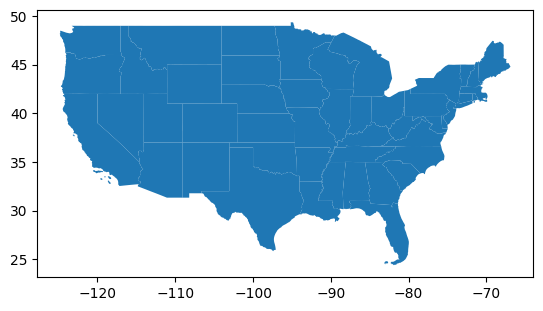

In [33]:
states.plot()

In [34]:
print(states.crs)
#5090 is a good coordinate reference system for the United States

EPSG:4269


<Axes: >

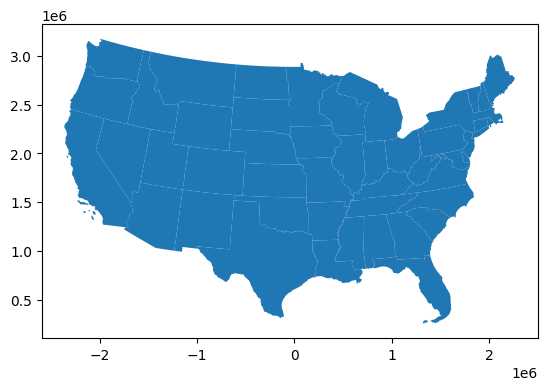

In [35]:
states_reprojected = states.to_crs(epsg=5070)
states_reprojected.plot()

Note that above I didn't write the name of the file like `../folder/filename.something`. That's because we're dealing with a [shapefile](https://en.wikipedia.org/wiki/Shapefile) which is really a folder with a bunch of files, rather than a single file. When reading a in a shapefile, you can just refer to the folder and GeoPandas will figure it out.

You can do `GeoDataFrame.head()` and it works a lot like `DataFrame.head()`.

The `geomoetry` column is the most important. All GeoDataFrames have `geometry` columns. This column can contain `Point` data--like the locations of cities or specific addresses, or `Polygon` data. In this case, we have polygons. Let's take a look with the handy `DataFrame.plot()` method.

Cool! Note that we can do a lot of things to make this look better. A lot of the aesthetics can be set right inside of the `plot` function. Others have to be set after you build the initial plot. 

By convention, we call the map object an `Axes` object. (Pronounced AXE-eez). It doesn't refer to the lines in a chart that mark the scale. It's a [Matplotlib concept](https://matplotlib.org/api/axes_api.html).

I won't go into what all these options mean, but check out the documention on how to plot at [the GeoPandas documentation site](http://geopandas.org/mapping.html).

Let's do it again with a counties map. You'll see how it's basically the same operation.

In [36]:
# read in the file and go straight to plotting!


In [39]:
bigfoot = pd.read_csv("bigfoot.csv")

**Making thematic maps with your merging powers**

I have a CSV of bigfoot sightings from the "official" [Geographic Database of Bigfood/Sasquatch Sightings and Reports](https://www.bfro.net/GDB/)

In [ ]:
bigfoot_geo = states_reprojected.merge(
    bigfoot,
    left_on="NAME",
    right_on="state"
)

SyntaxError: invalid syntax (3625369476.py, line 5)

In [42]:
bigfoot_geo.head()

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,state,sightings
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((1823794.312 2177067.513, 18237...",New York,108
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-1899752.494 2344539.921, -1899707.8...",Nevada,9
2,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((1890050.634 2591299.611, 1890055.031...",Vermont,9
3,1,1,09,01779780,09,0400000US09,CT,Connecticut,00,G4000,A,12542136566,1815978067,+41.5798095,-072.7466313,"POLYGON ((1933885.512 2258940.671, 1932099.761...",Connecticut,16
4,3,5,10,01779781,10,0400000US10,DE,Delaware,00,G4000,A,5046806302,1399105001,+38.9988742,-075.4422351,"POLYGON ((1728072.139 2038874.207, 1728079.162...",Delaware,5


Text(0.5, 1.0, 'Bigfoot Sightings by State')

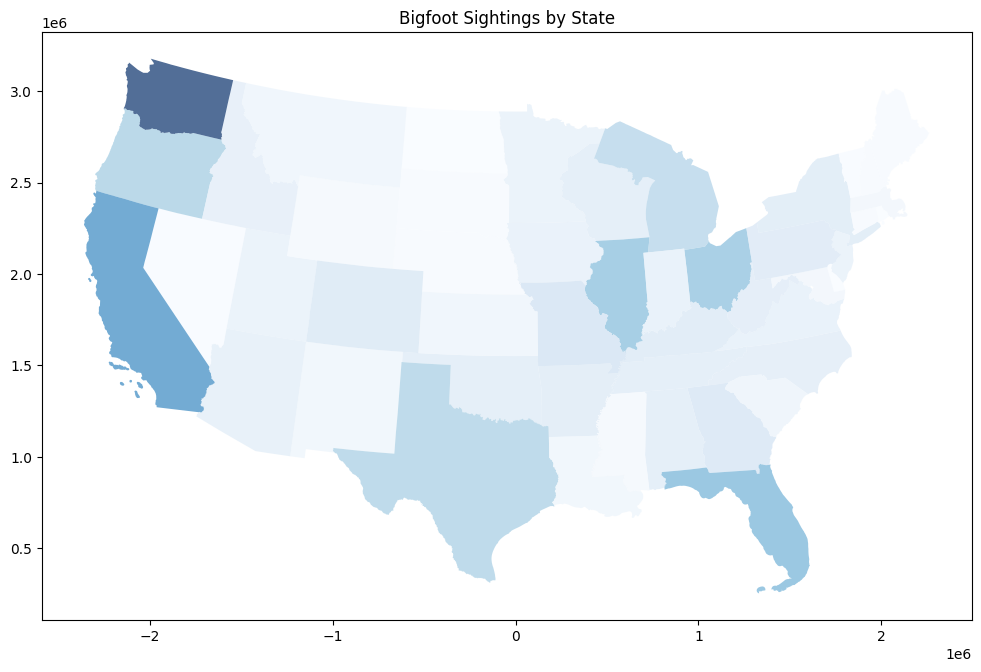

In [48]:
ax = bigfoot_geo.plot(
    column="sightings",
    cmap="Blues",
    figsize=(12, 8),
    alpha=0.7
)
ax.set_title("Bigfoot Sightings by State")

Note that I use Pandas to open this file because it's not a GeoDataFrame...yet

To make it a GeoDataFrame, we'll need to merge the bigfoot data with one of our shapefiles. We'll use the state shapefile from above because we can use the state name as a key. Take a look at it again:

Nice! But the color scheme is just awful. Let's use the [colormaps](https://matplotlib.org/users/colormaps.html) from matplotlib.

Want to save it as a file? It's a bit of an odd process but it's not hard.

In [ ]:
# first, get the "Figure" from the plot object.


# then, use the savefig method on that Figure object


